# DATA-549: Homework Assignment 7

## Instructions

- This homework assignment is worth **55** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

# Exercise 1 

In this exercise, we will work with the `winemag-data-130k-v2.csv` data file. This file contains information about wine. The goal is to explore this data using the NLP techniques that we have learnt. For more information about the data file, see this [link](https://www.kaggle.com/datasets/zynicide/wine-reviews/data).

### Exercise 1(a) (2 points)

Load the following libraries as follows:

```
import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `wine_df`.

In [2]:
wine_df = pd.read_csv("DATA/winemag-data-130k-v2.csv")
wine_df.head() 

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


### Exercise 1(c) (3 points)

Using the `string` library, remove all the punctuation of the `description` column and store the results in another column called `description_clean`.

In [3]:
import string

wine_df["description_clean"] = wine_df["description"].str.translate(
    str.maketrans("", "", string.punctuation)
)
wine_df[["description", "description_clean"]].head()

,description,description_clean
0,"Aromas include tropical fruit, broom, brimston...",Aromas include tropical fruit broom brimstone ...
1,"This is ripe and fruity, a wine that is smooth...",This is ripe and fruity a wine that is smooth ...
2,"Tart and snappy, the flavors of lime flesh and...",Tart and snappy the flavors of lime flesh and ...
3,"Pineapple rind, lemon pith and orange blossom ...",Pineapple rind lemon pith and orange blossom s...
4,"Much like the regular bottling from 2012, this...",Much like the regular bottling from 2012 this ...


### Exercise 1(d) (10 points)

Using the `nltk` library, remove stopwords, pronouns, and the following words: `drink`, `now`, `wine`, `flavor`, and `flavors` from `description_clean` and store in another column called `'description_clean_1'`. 

In [4]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
pronouns = {
    "i", "me", "my", "mine", "myself", "we", "us", "our", "ours", "ourselves",
    "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself",
    "she", "her", "hers", "herself", "it", "its", "itself", "they", "them", "their",
    "theirs", "themselves", "who", "whom", "whose", "what", "which"
}
extra_words = {"drink", "now", "wine", "flavor", "flavors"}

def clean_description(text):
    words = str(text).lower().split()
    return " ".join(
        word for word in words
        if word not in stop_words and word not in pronouns and word not in extra_words
    )

wine_df["description_clean_1"] = wine_df["description_clean"].apply(clean_description)
wine_df[["description_clean", "description_clean_1"]].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,description_clean,description_clean_1
0,Aromas include tropical fruit broom brimstone ...,aromas include tropical fruit broom brimstone ...
1,This is ripe and fruity a wine that is smooth ...,ripe fruity smooth still structured firm tanni...
2,Tart and snappy the flavors of lime flesh and ...,tart snappy lime flesh rind dominate green pin...
3,Pineapple rind lemon pith and orange blossom s...,pineapple rind lemon pith orange blossom start...
4,Much like the regular bottling from 2012 this ...,much like regular bottling 2012 comes across r...


### Exercise 1(e) (10 points)

Perform Lemmatization of `description_clean_1` and store the results in another column called `description_clean_2` in the `wine_df` data frame.

In [5]:
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
lemmatizer = WordNetLemmatizer()
wine_df["description_clean_2"] = wine_df["description_clean_1"].apply(
    lambda text: " ".join(lemmatizer.lemmatize(word) for word in text.split())
)
wine_df[["description_clean_1", "description_clean_2"]].head()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,description_clean_1,description_clean_2
0,aromas include tropical fruit broom brimstone ...,aroma include tropical fruit broom brimstone d...
1,ripe fruity smooth still structured firm tanni...,ripe fruity smooth still structured firm tanni...
2,tart snappy lime flesh rind dominate green pin...,tart snappy lime flesh rind dominate green pin...
3,pineapple rind lemon pith orange blossom start...,pineapple rind lemon pith orange blossom start...
4,much like regular bottling 2012 comes across r...,much like regular bottling 2012 come across ra...


### Exercise 1(f) (5 points)

Based on the results from part 1(g), we see digits in some of the text in `description_clean_2`. Remove all the digits from `description_clean_2` and store the results in another column `description_clean_3` in the `wine_df` data frame.

In [6]:
wine_df["description_clean_3"] = wine_df["description_clean_2"].str.replace(
    r"\d+", "", regex=True
)
wine_df[["description_clean_2", "description_clean_3"]].head()

,description_clean_2,description_clean_3
0,aroma include tropical fruit broom brimstone d...,aroma include tropical fruit broom brimstone d...
1,ripe fruity smooth still structured firm tanni...,ripe fruity smooth still structured firm tanni...
2,tart snappy lime flesh rind dominate green pin...,tart snappy lime flesh rind dominate green pin...
3,pineapple rind lemon pith orange blossom start...,pineapple rind lemon pith orange blossom start...
4,much like regular bottling 2012 come across ra...,much like regular bottling come across rather...


### Exercise 1(g) (5 points)

Generate embeddings using the `BERT` model on `description_clean_3`.

In [7]:
from sentence_transformers import SentenceTransformer

print("Loading the BERT-based sentence embedding model...")
bert_model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
bert_embeddings = bert_model.encode(
    wine_df["description_clean_3"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
)
print(f"BERT embedding shape: {bert_embeddings.shape}")

Loading the BERT-based sentence embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/2031 [00:00<?, ?it/s]

BERT embedding shape: (129971, 384)


### Exercise 1(h) (5 points)

Compute and visualize the principal components of the bert embedding.

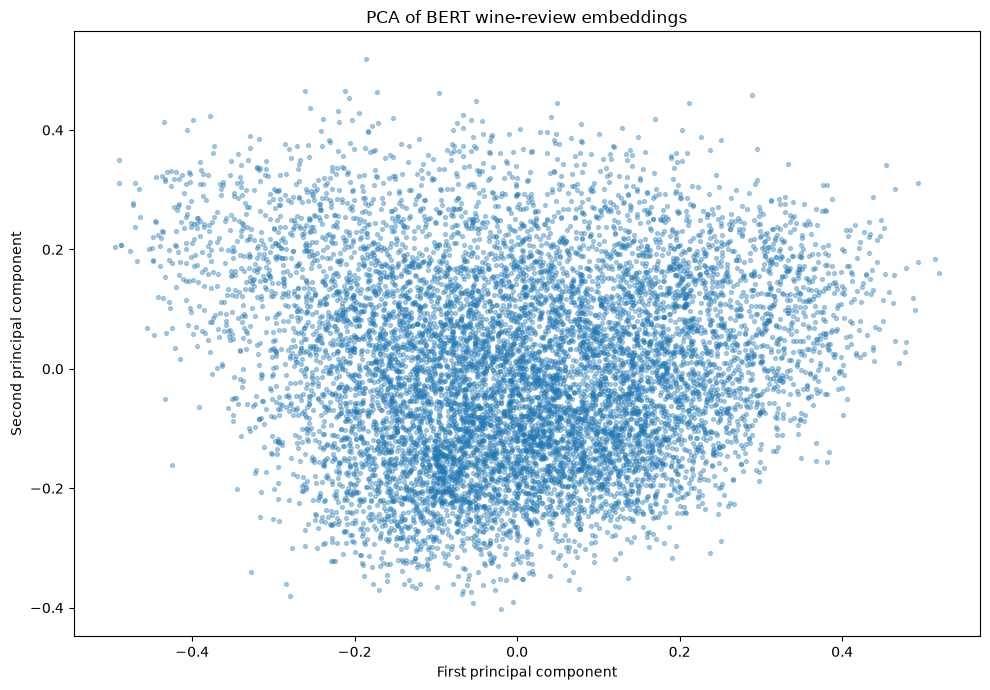

Explained variance ratio: [0.05686869 0.04726163]
Total variance explained: 0.10413033


In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
bert_pca = pca.fit_transform(bert_embeddings)

plot_size = min(10000, len(bert_pca))
plot_indices = np.random.default_rng(42).choice(
    len(bert_pca), size=plot_size, replace=False
)
plt.figure(figsize=(10, 7))
plt.scatter(
    bert_pca[plot_indices, 0], bert_pca[plot_indices, 1],
    s=8, alpha=0.35
)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("PCA of BERT wine-review embeddings")
plt.tight_layout()
plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

### Exercise 1(i) (5 points)

Estimate the number of clusters on the bert embedding using silhouette, Calinski Harabasz, and Davies Bouldin scores. Consider 2 to 6 clusters.

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

cluster_counts = range(2, 7)
score_size = min(10000, len(bert_embeddings))
score_indices = np.random.default_rng(42).choice(
    len(bert_embeddings), size=score_size, replace=False
)
score_embeddings = bert_embeddings[score_indices]
cluster_results = []

for k in cluster_counts:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = kmeans.fit_predict(score_embeddings)
    cluster_results.append({
        "k": k,
        "silhouette": silhouette_score(score_embeddings, sample_labels),
        "calinski_harabasz": calinski_harabasz_score(score_embeddings, sample_labels),
        "davies_bouldin": davies_bouldin_score(score_embeddings, sample_labels),
    })

cluster_scores = pd.DataFrame(cluster_results).set_index("k")
display(cluster_scores)
print("Best k by silhouette (higher is better):", cluster_scores["silhouette"].idxmax())
print("Best k by Calinski-Harabasz (higher is better):", cluster_scores["calinski_harabasz"].idxmax())
print("Best k by Davies-Bouldin (lower is better):", cluster_scores["davies_bouldin"].idxmin())
print(f"All three scores use the same reproducible {score_size:,}-review sample of the BERT embeddings.")

,silhouette,calinski_harabasz,davies_bouldin
k,,,
2,0.037861,400.650653,4.939768
3,0.036405,346.785393,4.538134
4,0.032804,292.716651,4.497177
5,0.028621,256.256748,4.678986
6,0.025909,227.281445,4.590230


Best k by silhouette (higher is better): 2
Best k by Calinski-Harabasz (higher is better): 2
Best k by Davies-Bouldin (lower is better): 4
All three scores use the same reproducible 10,000-review sample of the BERT embeddings.


# Exercise 2 

In this exercise, you will answer conceptual questions based on Chapter 7 (Getting Started with Information Extraction). No code is required.

### Exercise 2(a) (3 points)

The Levenshtein distance counts the minimum number of single-character edits (insertions, deletions, and substitutions, each with cost 1) needed to transform one string into another. What is the Levenshtein distance between the strings `flaw` and `lawn`?

- **A.** 1
- **B.** 2
- **C.** 3
- **D.** 4

**Answer:** b

### Exercise 2(b) (5 points)

Suppose you apply VADER (a lexicon-based sentiment analyzer) to the `description` column of the wine reviews. Describe **two** specific limitations of lexicon-based sentiment analysis that could cause VADER to misjudge these reviews. For each limitation, (i) name it, (ii) give a short wine-review style example sentence where it would fail, and (iii) explain why VADER fails on that example.

A phrase like “austere, mineral finish” may sound unfavorable to VADER even when the reviewer means it as praise, since wine terms depend on context. Likewise, “A lovely bottle...if you enjoy sour grapes” uses praise ironically... VADER may focus on “lovely” and miss the criticism.